# Real vs. AI-Generated Face Detection with Convolutional Neural Networks
**Machine Learning Project | Hiba Zormati**

This notebook investigates whether a supervised convolutional neural network (CNN) can distinguish real face images from images generated by StyleGAN in the **TheKernel01/140k-Real-and-Fake-Faces** dataset.





**Labels:** `0 = real`, `1 = fake`. A false negative (FN) is a fake image predicted as real; a false positive (FP) is a real image predicted as fake.

## 1. Introduction and research question

### 1.1 Context and problem

Image-generation systems can create highly realistic synthetic faces. This creates a need for tools that can help distinguish authentic photographs from generated images. Such tools are imperfect and should be treated as decision-support systems, not as definitive proof of authenticity.

### 1.2 Research question

**To what extent can a CNN trained on real FFHQ faces and StyleGAN-generated faces distinguish the two classes on held-out images from the same dataset distribution?**

### 1.3 Objectives

- Inspect the dataset and verify its actual structure, labels, image properties, and split sizes.
- Build a reproducible supervised-learning pipeline using PyTorch.
- Compare a simple pixel-based baseline with a CNN.
- Evaluate the selected model with threshold-based and ranking metrics.
- Inspect errors, calibration, and visual explanations where feasible.
- Discuss dataset bias and the difference between in-dataset performance and generalization to other generators or real-world images.

The contribution is an auditable experimental pipeline, including saved data indices, checkpointing, metric calculation, and explicit limitations. No performance result is assumed in advance.

## 2. Related work

### 2.1 Generative adversarial networks and StyleGAN

Generative Adversarial Networks (GANs) train a generator to create samples and a discriminator to distinguish generated samples from real training data. StyleGAN introduced a style-based generator architecture that improved control over image synthesis and enabled highly realistic face generation.

### 2.2 Convolutional neural networks

A CNN applies learnable filters (kernels) across an image. Early layers may respond to simple patterns such as edges; deeper layers can combine these patterns into more complex features. Pooling reduces spatial dimensions, while batch normalization can stabilize training. The final layer in this notebook outputs a **logit**: a real-valued score converted to a probability with the sigmoid function.

### 2.3 Detecting synthetic images and the generalization problem

Detection methods may exploit subtle frequency patterns or other artifacts left by a generator or image-processing pipeline. However, a model can learn dataset-specific shortcuts such as compression, resizing, backgrounds, or source-specific texture differences. Strong results on one dataset do not guarantee performance on images produced by newer generators or processed differently.

### 2.4 Positioning of this project

This project is a controlled binary-classification experiment on one dataset. Its main test set estimates performance on held-out examples from that dataset; it does **not** establish universal detection ability. The optional FaceForensics++ analysis is separate because it concerns manipulated video frames and has a different data-generation process.

## 3. Data

### 3.1 Source and labels

Dataset: [TheKernel01/140k-Real-and-Fake-Faces on Hugging Face](https://huggingface.co/datasets/TheKernel01/140k-Real-and-Fake-Faces).

The dataset is described as containing 140,000 images: 70,000 real faces from FFHQ and 70,000 StyleGAN-generated faces. The advertised official split sizes are 100,000 training, 20,000 validation, and 20,000 test examples. These are claims to verify below; actual usable counts may differ after exclusions or index filtering.

In [ ]:
# 3.2 Environment, Drive, and persistent project directory
import os, sys, json, time, random, hashlib, io, warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# If you added a shortcut to the shared folder in My Drive, this path should work.
PROJECT_DIR = Path("/content/drive/MyDrive/ai_face_detection") if IN_COLAB else Path("./ai_face_detection")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR.resolve())
print("Directory exists:", PROJECT_DIR.exists())
print("Existing files:")
for p in sorted(PROJECT_DIR.iterdir()):
    if p.is_file():
        print(f"  {p.name:32s} {p.stat().st_size / (1024**2):8.2f} MB")

Mounted at /content/drive
Project directory: /content/drive/.shortcut-targets-by-id/1QOUD50HurKcnB7PexrBkKpN-NpHqgWK6/ai_face_detection
Directory exists: True
Existing files:
  best.pt                              1.52 MB
  ffpp_crops.npy                    1875.00 MB
  ffpp_frames.csv                      0.78 MB
  ffpp_results.csv                     0.00 MB
  ffpp_video_scores.csv                0.07 MB
  hashes.csv                           9.04 MB
  history.json                         0.00 MB
  last.pt                              4.54 MB
  norm_mean.npy                        0.00 MB
  norm_std.npy                         0.00 MB
  predictions.npz                      0.74 MB
  removed_duplicates.csv               0.01 MB
  robustness.csv                       0.00 MB
  test_idx.npy                         0.15 MB
  val_idx.npy                          0.15 MB


In [ ]:
# Install only the packages needed for the main workflow.
%pip -q install datasets scikit-learn matplotlib pillow torchvision

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from datasets import load_dataset, load_dataset_builder, Image as HFImage

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score, roc_curve, precision_recall_curve
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("No GPU detected. Data inspection is possible; full CNN training may be very slow.")

Python: 3.13.15
PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
GPU memory (GiB): 14.56


### 3.3 Inspect dataset metadata before downloading all examples

The builder metadata gives the published feature schema and split information. It is useful as an initial check, but the loaded dataset and subsequent integrity checks determine the actual counts used in this experiment.

In [ ]:
DATASET_ID = "TheKernel01/140k-Real-and-Fake-Faces"
builder = load_dataset_builder(DATASET_ID)
print("Features:", builder.info.features)
print("Published split metadata:", builder.info.splits)

README.md:   0%|          | 0.00/5.06k [00:00<?, ?B/s]

Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['real', 'fake']), 'generator': ClassLabel(names=['Real', 'StyleGAN'])}
Published split metadata: {'train': SplitInfo(name='train', num_bytes=2853342700, num_examples=100000), 'validation': SplitInfo(name='validation', num_bytes=572215260, num_examples=20000), 'test': SplitInfo(name='test', num_bytes=570813220, num_examples=20000)}


In [ ]:
# Load the official dataset splits. Hugging Face caches downloaded data between sessions
# only if the cache is preserved; this notebook does not assume temporary files survive.
ds = load_dataset(DATASET_ID)
print(ds)
for split in ds:
    print(f"{split}: {len(ds[split]):,} rows")
    print("  Features:", ds[split].features)

data/train-00000-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  478MB            

data/train-00000-of-00006.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  479MB            

data/train-00001-of-00006.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00006.parquet: reconstructing file:   0%|          |  0.00B /  479MB            

data/train-00002-of-00006.parquet: downloading bytes:           |  0.00B            

... (14 outputs left out)

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/20000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'generator'],
        num_rows: 100000
    })
    validation: Dataset({
        features: ['image', 'label', 'generator'],
        num_rows: 20000
    })
    test: Dataset({
        features: ['image', 'label', 'generator'],
        num_rows: 20000
    })
})
train: 100,000 rows
  Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['real', 'fake']), 'generator': ClassLabel(names=['Real', 'StyleGAN'])}
validation: 20,000 rows
  Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['real', 'fake']), 'generator': ClassLabel(names=['Real', 'StyleGAN'])}
test: 20,000 rows
  Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['real', 'fake']), 'generator': ClassLabel(names=['Real', 'StyleGAN'])}


In [ ]:
# Inspect class labels and any generator metadata actually present.
for split in ds:
    labels = np.asarray(ds[split]["label"])
    values, counts = np.unique(labels, return_counts=True)
    print(f"{split}: label counts =", dict(zip(values.tolist(), counts.tolist())))
    if "generator" in ds[split].column_names:
        gens = np.asarray(ds[split]["generator"])
        print("  generator counts:", dict(zip(*np.unique(gens, return_counts=True))))
        print("  label == generator fraction:", float(np.mean(labels == gens)))

train: label counts = {0: 50000, 1: 50000}
  generator counts: {np.int64(0): np.int64(50000), np.int64(1): np.int64(50000)}
  label == generator fraction: 1.0
validation: label counts = {0: 10000, 1: 10000}
  generator counts: {np.int64(0): np.int64(10000), np.int64(1): np.int64(10000)}
  label == generator fraction: 1.0
test: label counts = {0: 10000, 1: 10000}
  generator counts: {np.int64(0): np.int64(10000), np.int64(1): np.int64(10000)}
  label == generator fraction: 1.0


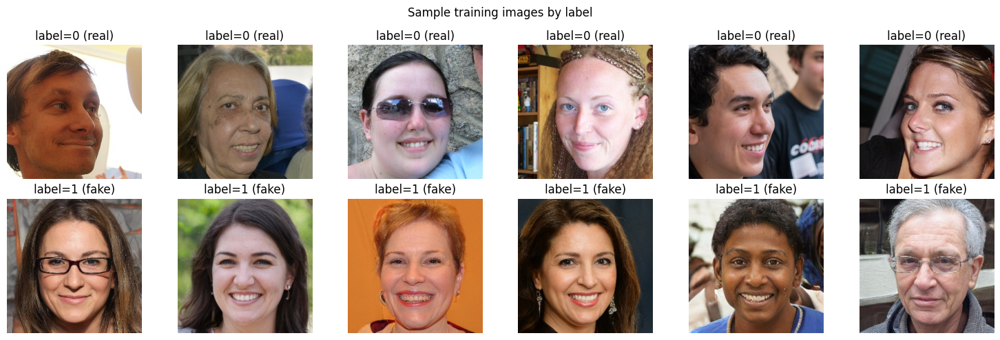

In [ ]:
# Display representative examples from each class.
train_labels = np.asarray(ds["train"]["label"])
label_names = ds["train"].features["label"].names if hasattr(ds["train"].features["label"], "names") else None
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for row, label in enumerate([0, 1]):
    candidates = np.where(train_labels == label)[0]
    chosen = rng.choice(candidates, size=min(6, len(candidates)), replace=False)
    for col, idx in enumerate(chosen):
        img = ds["train"][int(idx)]["image"]
        axes[row, col].imshow(img)
        name = label_names[label] if label_names else ("real" if label == 0 else "fake")
        axes[row, col].set_title(f"label={label} ({name})")
        axes[row, col].axis("off")
plt.suptitle("Sample training images by label")
plt.tight_layout()
plt.show()

In [ ]:
# Inspect dimensions, color modes, and decoding on a random sample.
from collections import Counter
sizes, modes, formats, decode_errors = Counter(), Counter(), Counter(), []
sample_n = min(1000, len(ds["train"]))
sample_indices = rng.choice(len(ds["train"]), size=sample_n, replace=False)
for idx in tqdm(sample_indices, desc="Sample image inspection"):
    try:
        img = ds["train"][int(idx)]["image"]
        img.load()
        sizes[img.size] += 1
        modes[img.mode] += 1
        formats[str(img.format)] += 1
    except Exception as exc:
        decode_errors.append((int(idx), str(exc)))
print("Image sizes in sample:", sizes)
print("Color modes in sample:", modes)
print("Formats reported by decoder:", formats)
print("Decode errors in sample:", len(decode_errors))

Sample image inspection:   0%|          | 0/1000 [00:00<?, ?it/s]

Image sizes in sample: Counter({(256, 256): 1000})
Color modes in sample: Counter({'RGB': 1000})
Formats reported by decoder: Counter({'JPEG': 1000})
Decode errors in sample: 0


### 3.4 Integrity and duplicate audit

An exact byte hash can identify identical files. A perceptual hash (here, difference hash or dHash) finds visually similar candidates, but collisions are possible. Similarity is therefore a **candidate-generation method**, not proof that two images are duplicates.



In [ ]:
RUN_FULL_HASH_AUDIT = False  # Set True to scan all images;
HASH_FILE = PROJECT_DIR / "hashes.csv"
BAD_FILE = PROJECT_DIR / "unreadable_images.csv"

def dhash(img, hash_size=8):
    gray = img.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS)
    arr = np.asarray(gray, dtype=np.int16)
    bits = (arr[:, 1:] > arr[:, :-1]).ravel()
    return "".join("1" if b else "0" for b in bits)

if RUN_FULL_HASH_AUDIT:
    records, bad = [], []
    for split in ["train", "validation", "test"]:
        raw = ds[split].cast_column("image", HFImage(decode=False))
        for idx, ex in enumerate(tqdm(raw, desc=f"Hashing {split}")):
            try:
                raw_bytes = ex["image"]["bytes"]
                with Image.open(io.BytesIO(raw_bytes)) as im:
                    im.load()
                    records.append((split, idx, int(ex["label"]),
                                    hashlib.md5(raw_bytes).hexdigest(), dhash(im)))
            except Exception as exc:
                bad.append((split, idx, repr(exc)))
    hashes_df = pd.DataFrame(records, columns=["split", "idx", "label", "md5", "dhash"])
    bad_df = pd.DataFrame(bad, columns=["split", "idx", "error"])
    hashes_df.to_csv(HASH_FILE, index=False)
    bad_df.to_csv(BAD_FILE, index=False)
    print("Hash records:", len(hashes_df), "| decode errors:", len(bad_df))
else:
    if HASH_FILE.exists():
        hashes_df = pd.read_csv(HASH_FILE)
        print("Loaded saved hash audit:", hashes_df.shape)
    else:
        hashes_df = None
        print("Full hash audit skipped. Set RUN_FULL_HASH_AUDIT=True to run it.")

Loaded saved hash audit: (140000, 5)


In [ ]:
if hashes_df is not None:
    for col in ["md5", "dhash"]:
        duplicate_rows = hashes_df[hashes_df.duplicated(col, keep=False)]
        split_counts = hashes_df.groupby(col)["split"].nunique()
        label_counts = hashes_df.groupby(col)["label"].nunique()
        print(f"\n{col}: rows in repeated groups={len(duplicate_rows):,}")
        print("Groups spanning multiple splits:", int((split_counts > 1).sum()))
        print("Groups with conflicting labels:", int((label_counts > 1).sum()))
    print("\nRows by split in audit:", hashes_df["split"].value_counts().to_dict())


md5: rows in repeated groups=0
Groups spanning multiple splits: 0
Groups with conflicting labels: 0

dhash: rows in repeated groups=2,912
Groups spanning multiple splits: 645
Groups with conflicting labels: 4

Rows by split in audit: {'train': 100000, 'validation': 20000, 'test': 20000}


cross-split candidate groups: 645


  0%|          | 0/645 [00:00<?, ?it/s]

random pairs  : median MSE = 6442, 5th percentile = 3421
label-conflict: MSE = [2895.]
candidates    : median = 135, min = 15.1, share below 20 = 0.31%


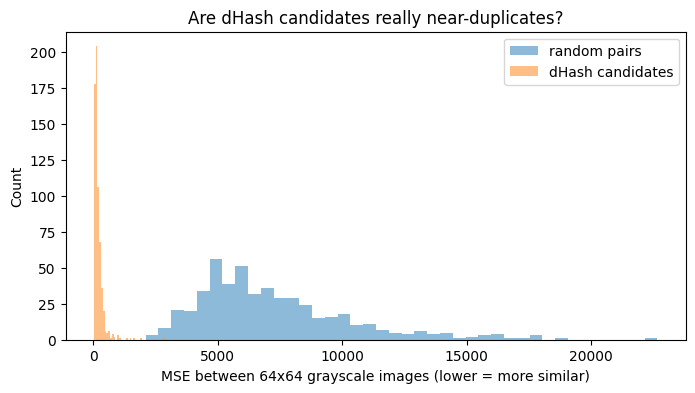

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from PIL import Image

def small(split, idx):
    """64x64 grayscale version of image (split, idx)."""
    img = ds[split][int(idx)]["image"].convert("L").resize((64, 64), Image.LANCZOS)
    return np.asarray(img, dtype=np.float32)

# Groups that share a dHash AND appear in more than one split
cross = [g for _, g in df.groupby("dhash") if g["split"].nunique() > 1]
print("cross-split candidate groups:", len(cross))

results = []   # (min MSE across split pairs, has_conflicting_labels, group)
for g in tqdm(cross):
    rows = list(g.itertuples())
    ims = [small(r.split, r.idx) for r in rows]
    best = min(np.mean((ims[a] - ims[b]) ** 2)
               for a in range(len(rows)) for b in range(a + 1, len(rows))
               if rows[a].split != rows[b].split)
    results.append((best, g["label"].nunique() > 1, g))

mse_all  = np.array([r[0] for r in results])
mse_ctrl = np.array([r[0] for r in results if r[1]])   # known non-duplicates

# Random-pair baseline: MSE between two unrelated images
rng = np.random.default_rng(42)
pairs = rng.integers(0, len(df), size=(500, 2))
mse_rand = np.array([
    np.mean((small(df.split[a], df.idx[a]) - small(df.split[b], df.idx[b])) ** 2)
    for a, b in pairs if a != b
])

print(f"random pairs  : median MSE = {np.median(mse_rand):.0f}, "
      f"5th percentile = {np.percentile(mse_rand, 5):.0f}")
print(f"label-conflict: MSE = {np.round(mse_ctrl, 0)}")
print(f"candidates    : median = {np.median(mse_all):.0f}, "
      f"min = {mse_all.min():.1f}, share below 20 = {(mse_all < 20).mean():.2%}")

plt.figure(figsize=(8, 4))
plt.hist(mse_rand, bins=40, alpha=0.5, label="random pairs")
plt.hist(mse_all, bins=40, alpha=0.5, label="dHash candidates")
plt.xlabel("MSE between 64x64 grayscale images (lower = more similar)")
plt.ylabel("Count"); plt.title("Are dHash candidates really near-duplicates?")
plt.legend(); plt.show()

In [ ]:
from itertools import combinations

pair_rows = []
for g in tqdm(cross):
    rows = list(g.itertuples())
    ims = {(r.split, r.idx): small(r.split, r.idx) for r in rows}
    for a, b in combinations(rows, 2):
        if a.split != b.split:
            mse = np.mean((ims[(a.split, a.idx)] - ims[(b.split, b.idx)]) ** 2)
            pair_rows.append(dict(a_split=a.split, a_idx=a.idx, a_label=a.label,
                                  b_split=b.split, b_idx=b.idx, b_label=b.label, mse=mse))
pp = pd.DataFrame(pair_rows)
print("cross-split pairs compared:", len(pp))

print("\npairs below each MSE threshold:")
for t in [50, 100, 200, 500, 1000, 2000, 3000]:
    print(f"  MSE < {t:>4}: {(pp.mse < t).sum()}")

low = pp[pp.mse < 500]
print("\nlabel of pairs with MSE < 500 (a_label):", low["a_label"].value_counts().to_dict())
print("pairs with MSE < 500 but different labels:", (low.a_label != low.b_label).sum())

  0%|          | 0/645 [00:00<?, ?it/s]

cross-split pairs compared: 725

pairs below each MSE threshold:
  MSE <   50: 68
  MSE <  100: 251
  MSE <  200: 500
  MSE <  500: 696
  MSE < 1000: 719
  MSE < 2000: 724
  MSE < 3000: 725

label of pairs with MSE < 500 (a_label): {1: 696}
pairs with MSE < 500 but different labels: 0


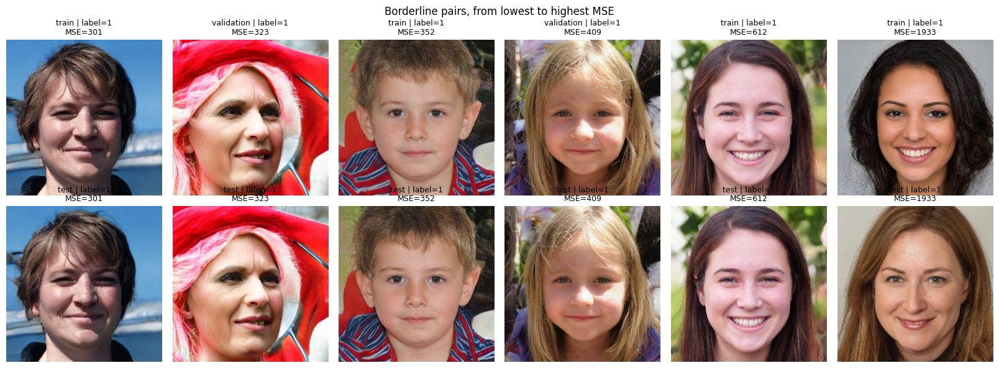

In [ ]:
border = pp[(pp.mse >= 300) & (pp.mse < 2000)].sort_values("mse")
sample = border.iloc[np.linspace(0, len(border) - 1, 6).astype(int)] if len(border) >= 6 else border

fig, axes = plt.subplots(2, len(sample), figsize=(2.7 * len(sample), 6), squeeze=False)
for col, r in enumerate(sample.itertuples()):
    for row, (s, i, l) in enumerate([(r.a_split, r.a_idx, r.a_label), (r.b_split, r.b_idx, r.b_label)]):
        axes[row, col].imshow(ds[s][int(i)]["image"])
        axes[row, col].set_title(f"{s} | label={l}\nMSE={r.mse:.0f}", fontsize=9)
        axes[row, col].axis("off")
plt.suptitle("Borderline pairs, from lowest to highest MSE")
plt.tight_layout(); plt.show()

In [ ]:
THRESH = 1000

prio = {"train": 0, "validation": 1, "test": 2}
confirmed = pp[pp.mse < THRESH]

to_remove = set()
for r in confirmed.itertuples():
    # remove the copy that lives in the lower-priority split
    if prio[r.a_split] > prio[r.b_split]:
        to_remove.add((r.a_split, int(r.a_idx)))
    else:
        to_remove.add((r.b_split, int(r.b_idx)))

removed = pd.DataFrame(sorted(to_remove), columns=["split", "idx"])
removed.to_csv("removed_duplicates.csv", index=False)   # keep this for the report

print("images to remove per split:\n", removed["split"].value_counts().to_dict())

# class balance of what remains in each split
for split in ["validation", "test"]:
    rem = removed[removed.split == split]["idx"].tolist()
    labels = np.array(ds[split]["label"])
    keep = np.ones(len(labels), bool); keep[rem] = False
    print(split, "-> kept", keep.sum(), "| class counts:", dict(Counter(labels[keep])))

images to remove per split:
 {'test': 347, 'validation': 312}
validation -> kept 19688 | class counts: {np.int64(0): 10000, np.int64(1): 9688}
test -> kept 19653 | class counts: {np.int64(0): 10000, np.int64(1): 9653}


pairs in 500-1000: 23 | in 1000-2000: 5


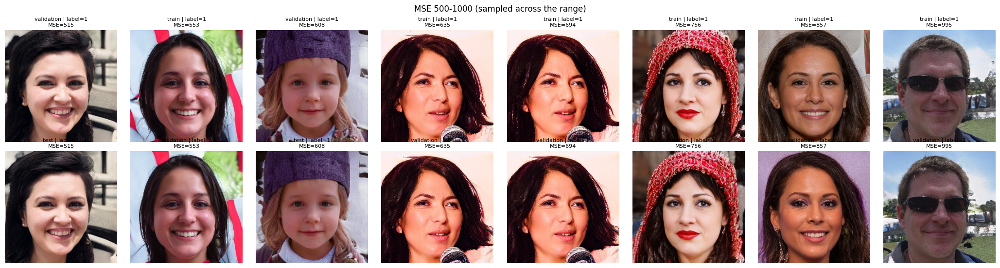

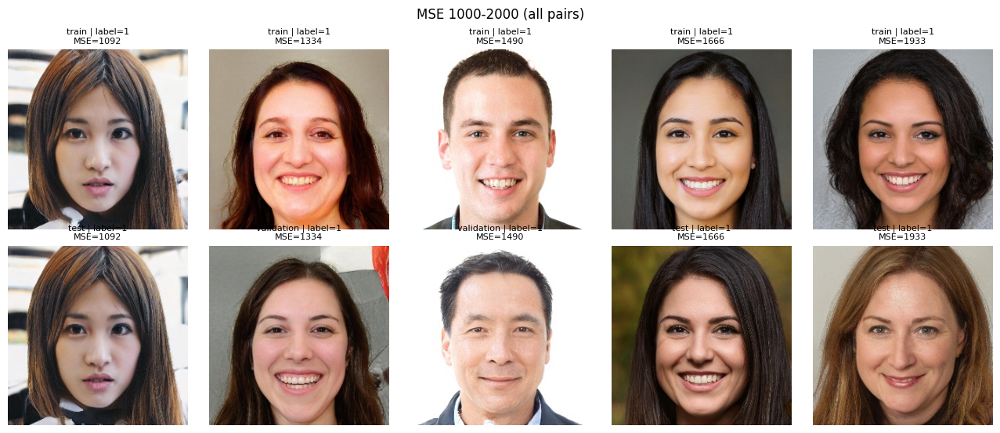

In [ ]:
def show_pairs(sub, title):
    n = len(sub)
    fig, axes = plt.subplots(2, n, figsize=(2.6 * n, 5.6), squeeze=False)
    for col, r in enumerate(sub.itertuples()):
        for row, (s, i, l) in enumerate([(r.a_split, r.a_idx, r.a_label),
                                         (r.b_split, r.b_idx, r.b_label)]):
            axes[row, col].imshow(ds[s][int(i)]["image"])
            axes[row, col].set_title(f"{s} | label={l}\nMSE={r.mse:.0f}", fontsize=8)
            axes[row, col].axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

zone1 = pp[(pp.mse >= 500) & (pp.mse < 1000)].sort_values("mse")
zone2 = pp[(pp.mse >= 1000) & (pp.mse < 2000)].sort_values("mse")
print("pairs in 500-1000:", len(zone1), "| in 1000-2000:", len(zone2))

# spread the 8 displayed pairs across the whole 500-1000 range
pick = zone1.iloc[np.linspace(0, len(zone1) - 1, min(8, len(zone1))).astype(int)]
show_pairs(pick, "MSE 500-1000 (sampled across the range)")
show_pairs(zone2, "MSE 1000-2000 (all pairs)")

In [ ]:
rng = np.random.default_rng(42)          # fixed seed: reproducible

def balanced_indices(split):
    labels = np.array(ds[split]["label"])
    drop = set(removed[removed.split == split]["idx"])
    keep = np.array([i for i in range(len(labels)) if i not in drop])
    n = min((labels[keep] == 0).sum(), (labels[keep] == 1).sum())
    chosen = np.concatenate([rng.choice(keep[labels[keep] == c], n, replace=False)
                             for c in (0, 1)])
    return np.sort(chosen)

val_idx  = balanced_indices("validation")
test_idx = balanced_indices("test")
train_idx = np.arange(len(ds["train"]))   # train is untouched

for name, idx, split in [("validation", val_idx, "validation"), ("test", test_idx, "test")]:
    lab = np.array(ds[split]["label"])[idx]
    print(name, len(idx), dict(Counter(lab)))

np.save("val_idx.npy", val_idx); np.save("test_idx.npy", test_idx)

validation 19376 {np.int64(0): 9688, np.int64(1): 9688}
test 19306 {np.int64(0): 9653, np.int64(1): 9653}


### 3.5 Define evaluation indices

The official split boundaries are retained. If previous `val_idx.npy` and `test_idx.npy` files exist in the project folder, they are loaded and checked for validity. This preserves earlier evaluation subsets, but the exact subset sizes must be reported and interpreted carefully. Otherwise, all examples in the official validation and test splits are used.

If duplicate-cleaning indices from an earlier run are reused, the notebook records that fact; it does not assume the old threshold was scientifically definitive.

In [ ]:
def load_or_create_indices(split_name, n_rows):
    filename = "val_idx.npy" if split_name == "validation" else f"{split_name}_idx.npy"
    path = PROJECT_DIR / filename
    if path.exists():
        idx = np.load(path).astype(np.int64)
        if idx.ndim != 1 or len(idx) == 0 or idx.min() < 0 or idx.max() >= n_rows:
            raise ValueError(f"Invalid saved indices in {path}")
        print(f"Loaded {split_name} indices: {len(idx):,} / {n_rows:,}")
        return idx
    idx = np.arange(n_rows, dtype=np.int64)
    np.save(path, idx)
    print(f"Created full {split_name} indices: {len(idx):,}")
    return idx

val_idx = load_or_create_indices("validation", len(ds["validation"]))
test_idx = load_or_create_indices("test", len(ds["test"]))
train_idx = np.arange(len(ds["train"]), dtype=np.int64)

y_train_all = np.asarray(ds["train"]["label"], dtype=np.int64)
y_val = np.asarray(ds["validation"]["label"], dtype=np.int64)[val_idx]
y_test = np.asarray(ds["test"]["label"], dtype=np.int64)[test_idx]
print("Actual rows used — train:", len(train_idx), "validation:", len(val_idx), "test:", len(test_idx))
print("Validation labels:", dict(zip(*np.unique(y_val, return_counts=True))))
print("Test labels:", dict(zip(*np.unique(y_test, return_counts=True))))

Loaded validation indices: 19,376 / 20,000
Loaded test indices: 19,306 / 20,000
Actual rows used — train: 100000 validation: 19376 test: 19306
Validation labels: {np.int64(0): np.int64(9688), np.int64(1): np.int64(9688)}
Test labels: {np.int64(0): np.int64(9653), np.int64(1): np.int64(9653)}


## 4. Methodology

### 4.1 Supervised classification and preprocessing

Each image is paired with a binary label. Images are converted to RGB tensors and normalized using channel means and standard deviations estimated from a reproducible training sample. Horizontal flipping is used as a lightweight training augmentation; validation and test images are not randomly augmented.

### 4.2 Baseline and CNN

The baseline is logistic regression on small, resized RGB pixels. It is intentionally simple and helps determine whether coarse color/spatial information already separates the classes. The CNN learns spatial filters at multiple resolutions and uses binary cross-entropy with logits.

### 4.3 Training and model selection

The model is optimized with Adam. The checkpoint with the lowest validation loss is selected; early stopping halts training when validation loss does not improve for a fixed patience. The test set is used only for final evaluation and error analysis, not for choosing epochs or thresholds.

### 4.4 Metrics

Accuracy measures the fraction of correct predictions. Precision measures how many predicted fakes are truly fake; recall measures how many fake images are detected. F1 balances precision and recall. ROC-AUC and Average Precision use continuous scores and measure ranking quality. The default classification threshold is 0.5 unless a threshold is selected using validation data only.

## 5. Implementation

### 5.1 Reproducible transforms and DataLoaders

In [ ]:
# Estimate normalization from a modest reproducible sample of training images.
# This avoids decoding the entire dataset into RAM at once.
norm_path_mean, norm_path_std = PROJECT_DIR / "norm_mean.npy", PROJECT_DIR / "norm_std.npy"
if norm_path_mean.exists() and norm_path_std.exists():
    MEAN = np.load(norm_path_mean)
    STD = np.load(norm_path_std)
    print("Loaded saved normalization statistics.")
else:
    norm_sample_n = min(3000, len(ds["train"]))
    norm_sample_idx = rng.choice(len(ds["train"]), norm_sample_n, replace=False)
    channel_sum = np.zeros(3, dtype=np.float64)
    channel_sq_sum = np.zeros(3, dtype=np.float64)
    pixel_count = 0
    for idx in tqdm(norm_sample_idx, desc="Estimating RGB normalization"):
        arr = np.asarray(ds["train"][int(idx)]["image"].convert("RGB"), dtype=np.float32) / 255.0
        arr = arr.reshape(-1, 3)
        channel_sum += arr.sum(axis=0)
        channel_sq_sum += np.square(arr).sum(axis=0)
        pixel_count += len(arr)
    MEAN = channel_sum / pixel_count
    STD = np.sqrt(np.maximum(channel_sq_sum / pixel_count - MEAN**2, 1e-8))
    np.save(norm_path_mean, MEAN)
    np.save(norm_path_std, STD)
print("Mean:", MEAN)
print("Std:", STD)

Loaded saved normalization statistics.
Mean: [0.5183948  0.42540705 0.3809748 ]
Std: [0.28049286 0.25476255 0.2561189 ]


In [ ]:
class FaceDataset(Dataset):
    def __init__(self, hf_split, indices, transform):
        self.data = hf_split
        self.indices = np.asarray(indices, dtype=np.int64)
        self.transform = transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, position):
        row = self.data[int(self.indices[position])]
        image = row["image"].convert("RGB")
        x = self.transform(image)
        y = torch.tensor(float(row["label"]), dtype=torch.float32)
        return x, y

normalize = T.Normalize(mean=MEAN.tolist(), std=STD.tolist())
train_tf = T.Compose([T.RandomHorizontalFlip(p=0.5), T.ToTensor(), normalize])
eval_tf = T.Compose([T.ToTensor(), normalize])

BATCH_SIZE = 32 if torch.cuda.is_available() else 8
NUM_WORKERS = 2 if IN_COLAB else 0
def seed_worker(worker_id):
    np.random.seed(SEED + worker_id)

loader_common = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                     pin_memory=torch.cuda.is_available(), worker_init_fn=seed_worker)
train_loader = DataLoader(FaceDataset(ds["train"], train_idx, train_tf),
                          shuffle=True, **loader_common)
val_loader = DataLoader(FaceDataset(ds["validation"], val_idx, eval_tf),
                        shuffle=False, **loader_common)
test_loader = DataLoader(FaceDataset(ds["test"], test_idx, eval_tf),
                         shuffle=False, **loader_common)

xb, yb = next(iter(train_loader))
print("Batch shape:", tuple(xb.shape), "| labels:", tuple(yb.shape))
print("Batch label counts:", dict(zip(*np.unique(yb.numpy().astype(int), return_counts=True))))
print("Normalized value range:", float(xb.min()), "to", float(xb.max()))

Batch shape: (32, 3, 256, 256) | labels: (32,)
Batch label counts: {np.int64(0): np.int64(19), np.int64(1): np.int64(13)}
Normalized value range: -1.8481566905975342 to 2.416944742202759


### 5.2 Majority-class baseline

A majority-class classifier predicts the most common class in the validation set. For a balanced dataset this should be near 50% accuracy; the actual value is calculated rather than assumed.

In [ ]:
majority_label = int(np.bincount(y_val).argmax())
majority_accuracy = float(np.mean(y_val == majority_label))
print("Validation majority label:", majority_label)
print(f"Majority-class validation accuracy: {majority_accuracy:.4f}")

Validation majority label: 0
Majority-class validation accuracy: 0.5000


### 5.3 Pixel logistic-regression baseline

The baseline resizes images to 16 × 16 RGB pixels and fits logistic regression. This is computationally lighter than a CNN, but it may still take time because it decodes a large number of images. The training sample size is configurable.

In [ ]:
RUN_PIXEL_BASELINE = True
BASELINE_MAX_PER_CLASS = 5000

if RUN_PIXEL_BASELINE:
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    def pixel_features(split, indices, max_per_class=None):
        indices = np.asarray(indices, dtype=np.int64)
        labels = np.asarray(split["label"], dtype=np.int64)[indices]
        if max_per_class is not None:
            selected = []
            local_rng = np.random.default_rng(SEED)
            for lab in np.unique(labels):
                candidates = indices[labels == lab]
                selected.extend(local_rng.choice(candidates, min(max_per_class, len(candidates)), replace=False))
            indices = np.asarray(selected, dtype=np.int64)
            labels = np.asarray(split["label"], dtype=np.int64)[indices]
        X = []
        for idx in tqdm(indices, desc="Extracting 16x16 pixels"):
            im = split[int(idx)]["image"].convert("RGB").resize((16, 16), Image.Resampling.LANCZOS)
            X.append(np.asarray(im, dtype=np.float32).reshape(-1) / 255.0)
        return np.asarray(X), labels

    Xb_train, yb_train = pixel_features(ds["train"], train_idx, BASELINE_MAX_PER_CLASS)
    Xb_val, yb_val = pixel_features(ds["validation"], val_idx, BASELINE_MAX_PER_CLASS)
    baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
    baseline.fit(Xb_train, yb_train)
    baseline_prob = baseline.predict_proba(Xb_val)[:, 1]
    baseline_pred = (baseline_prob >= 0.5).astype(int)
    print("Pixel baseline — validation")
    print("Accuracy:", round(accuracy_score(yb_val, baseline_pred), 4))
    print("ROC-AUC:", round(roc_auc_score(yb_val, baseline_prob), 4))
else:
    print("Pixel baseline skipped by configuration.")

Extracting 16x16 pixels:   0%|          | 0/10000 [00:00<?, ?it/s]

Extracting 16x16 pixels:   0%|          | 0/10000 [00:00<?, ?it/s]

Pixel baseline — validation
Accuracy: 0.7403
ROC-AUC: 0.8081


### 5.4 CNN architecture

Each convolutional block contains a 3×3 convolution, batch normalization, ReLU activation, and 2×2 max pooling. Five blocks reduce the 256×256 image spatially while increasing the number of feature channels. Global average pooling summarizes each channel, and the final linear layer outputs one logit.

`BCEWithLogitsLoss` combines sigmoid and binary cross-entropy in a numerically stable form, so the model should return logits rather than sigmoid probabilities during training.

In [ ]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=False),
        nn.MaxPool2d(kernel_size=2)
    )

class SmallCNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 16), conv_block(16, 32), conv_block(32, 64),
            conv_block(64, 128), conv_block(128, 256)
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(256, 1))
    def forward(self, x):
        return self.head(self.pool(self.features(x))).squeeze(1)

model = SmallCNN().to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters: {n_params:,}")
with torch.no_grad():
    print("Output shape for one batch:", tuple(model(xb.to(device)).shape))

SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), 

### 5.5 Training with checkpoints and recovery

In [ ]:
# Adjust these settings before training.
EPOCHS = 15
PATIENCE = 4
LEARNING_RATE = 1e-3
RESUME_TRAINING = True
ALLOW_FULL_TRAINING = True

if device.type == "cpu" and ALLOW_FULL_TRAINING:
    print("WARNING: full training on CPU may be extremely slow. Set ALLOW_FULL_TRAINING=False to skip.")

In [ ]:
from contextlib import nullcontext

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

last_path = PROJECT_DIR / "last.pt"
best_path = PROJECT_DIR / "best.pt"
history_path = PROJECT_DIR / "history.json"
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
start_epoch, best_val_loss, bad_epochs = 0, float("inf"), 0

if RESUME_TRAINING and last_path.exists():
    checkpoint = torch.load(last_path, map_location=device)
    model.load_state_dict(checkpoint["model"])
    if "optimizer" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer"])
    if "scaler" in checkpoint and use_amp:
        scaler.load_state_dict(checkpoint["scaler"])
    history = checkpoint.get("history", history)
    best_val_loss = checkpoint.get("best_val_loss", checkpoint.get("best_val", float("inf")))
    bad_epochs = checkpoint.get("bad_epochs", 0)
    start_epoch = checkpoint.get("epoch", -1) + 1
    print(f"Resuming from epoch {start_epoch + 1}")
else:
    print("Starting a new training run.")

Resuming from epoch 16


In [ ]:
def run_epoch(model, loader, training):
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    grad_context = torch.enable_grad() if training else torch.no_grad()
    with grad_context:
        for images, labels in tqdm(loader, leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            amp_context = torch.autocast(device_type="cuda", dtype=torch.float16) if use_amp else nullcontext()
            with amp_context:
                logits = model(images)
                loss = criterion(logits, labels)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += float(loss.detach()) * len(labels)
            correct += int(((logits.detach() >= 0).float() == labels).sum())
            total += len(labels)
    return total_loss / max(total, 1), correct / max(total, 1)

if ALLOW_FULL_TRAINING:
    for epoch in range(start_epoch, EPOCHS):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, training=True)
        va_loss, va_acc = run_epoch(model, val_loader, training=False)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        improved = va_loss < best_val_loss
        if improved:
            best_val_loss, bad_epochs = va_loss, 0
            torch.save(model.state_dict(), best_path)
        else:
            bad_epochs += 1

        torch.save({
            "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(), "history": history, "epoch": epoch,
            "best_val_loss": best_val_loss, "bad_epochs": bad_epochs
        }, last_path)
        history_path.write_text(json.dumps(history, indent=2))
        print(f"Epoch {epoch+1}/{EPOCHS} | train loss {tr_loss:.4f}, acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f}, acc {va_acc:.4f} | {(time.time()-t0)/60:.1f} min"
              + (" | best checkpoint" if improved else ""))
        if bad_epochs >= PATIENCE:
            print(f"Early stopping after {PATIENCE} epochs without validation-loss improvement.")
            break
else:
    print("Training skipped by configuration. Load an existing best.pt only if it matches this model and data setup.")

### 5.6 Learning curves and best checkpoint

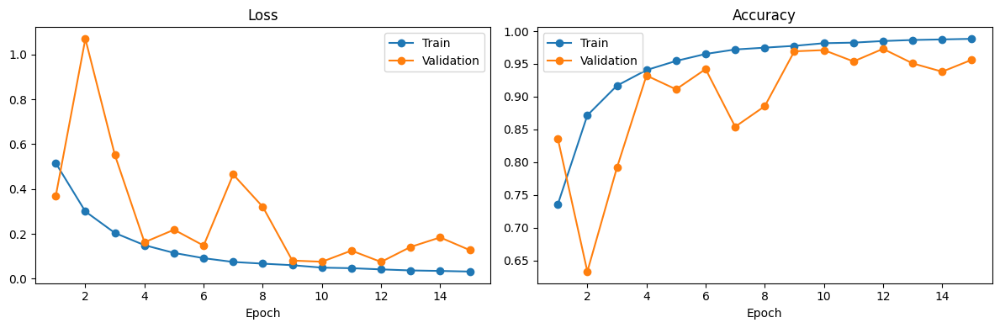

In [ ]:
if history["train_loss"]:
    epochs_seen = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs_seen, history["train_loss"], marker="o", label="Train")
    axes[0].plot(epochs_seen, history["val_loss"], marker="o", label="Validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(epochs_seen, history["train_acc"], marker="o", label="Train")
    axes[1].plot(epochs_seen, history["val_acc"], marker="o", label="Validation")
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    plt.tight_layout(); plt.show()
else:
    print("No training history is available in this session.")

In [ ]:
if not best_path.exists():
    raise FileNotFoundError(f"No best checkpoint found at {best_path}. Run training or point to a compatible checkpoint.")
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()
print("Loaded best checkpoint:", best_path)

Loaded best checkpoint: /content/drive/MyDrive/ai_face_detection/best.pt


## 6. Experimental protocol

In [ ]:
protocol = {
    "dataset": DATASET_ID,
    "seed": SEED,
    "device": str(device),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "pytorch_version": torch.__version__,
    "train_count": int(len(train_idx)),
    "validation_count": int(len(val_idx)),
    "test_count": int(len(test_idx)),
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "epochs_max": EPOCHS,
    "patience": PATIENCE,
    "learning_rate": LEARNING_RATE,
    "architecture": "SmallCNN: five Conv-BN-ReLU-MaxPool blocks; global average pooling; dropout; linear logit",
    "trainable_parameters": int(n_params),
    "normalization_mean": MEAN.tolist(),
    "normalization_std": STD.tolist(),
    "checkpoint_selection": "minimum validation BCE loss",
    "decision_threshold_default": 0.5,
}
print(json.dumps(protocol, indent=2))
(PROJECT_DIR / "experiment_protocol.json").write_text(json.dumps(protocol, indent=2))

{
  "dataset": "TheKernel01/140k-Real-and-Fake-Faces",
  "seed": 42,
  "device": "cuda",
  "gpu": "Tesla T4",
  "pytorch_version": "2.11.0+cu130",
  "train_count": 100000,
  "validation_count": 19376,
  "test_count": 19306,
  "batch_size": 32,
  "num_workers": 2,
  "epochs_max": 15,
  "patience": 4,
  "learning_rate": 0.001,
  "architecture": "SmallCNN: five Conv-BN-ReLU-MaxPool blocks; global average pooling; dropout; linear logit",
  "trainable_parameters": 393857,
  "normalization_mean": [
    0.5183947965135455,
    0.4254070514155645,
    0.38097479926219446
  ],
  "normalization_std": [
    0.28049285799192847,
    0.2547625504900712,
    0.2561189027818328
  ],
  "checkpoint_selection": "minimum validation BCE loss",
  "decision_threshold_default": 0.5
}


771

## 7. Results

### 7.1 Predictions and core metrics

In [ ]:
@torch.no_grad()
def predict_logits(model, loader):
    outputs = []
    model.eval()
    for images, _ in tqdm(loader, desc="Predicting"):
        images = images.to(device, non_blocking=True)
        amp_context = torch.autocast(device_type="cuda", dtype=torch.float16) if use_amp else nullcontext()
        with amp_context:
            logits = model(images)
        outputs.append(logits.float().cpu().numpy())
    return np.concatenate(outputs)

test_logits = predict_logits(model, test_loader)
val_logits = predict_logits(model, val_loader)
assert len(test_logits) == len(y_test) == len(test_idx)
assert len(val_logits) == len(y_val) == len(val_idx)

predictions_path = PROJECT_DIR / "predictions.npz"
np.savez(predictions_path, test_logits=test_logits, y_test=y_test, test_idx=test_idx,
         val_logits=val_logits, y_val=y_val, val_idx=val_idx)
print("Saved predictions:", predictions_path)

Predicting:   0%|          | 0/604 [00:00<?, ?it/s]

Predicting:   0%|          | 0/606 [00:00<?, ?it/s]

Saved predictions: /content/drive/MyDrive/ai_face_detection/predictions.npz


In [ ]:
def sigmoid_np(x):
    x = np.asarray(x, dtype=np.float64)
    # Numerically stable sigmoid
    out = np.empty_like(x)
    pos = x >= 0
    out[pos] = 1 / (1 + np.exp(-x[pos]))
    exp_x = np.exp(x[~pos])
    out[~pos] = exp_x / (1 + exp_x)
    return out

prob_val = sigmoid_np(val_logits)
prob_test = sigmoid_np(test_logits)
pred_val = (prob_val >= 0.5).astype(int)
pred_test = (prob_test >= 0.5).astype(int)

def report_metrics(y, prob, threshold=0.5, title="Evaluation"):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    print(f"--- {title} (n={len(y):,}, threshold={threshold:.3f}) ---")
    print(f"Accuracy:          {accuracy_score(y, pred):.4f}")
    print(f"Precision (fake):  {precision_score(y, pred, zero_division=0):.4f}")
    print(f"Recall (fake):     {recall_score(y, pred, zero_division=0):.4f}")
    print(f"F1 (fake):         {f1_score(y, pred, zero_division=0):.4f}")
    print(f"ROC-AUC:           {roc_auc_score(y, prob):.4f}")
    print(f"Average Precision: {average_precision_score(y, prob):.4f}")
    print(f"TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")
    print(classification_report(y, pred, labels=[0,1], target_names=["real", "fake"], digits=4, zero_division=0))
    return pred

_ = report_metrics(y_val, prob_val, 0.5, "Validation")
_ = report_metrics(y_test, prob_test, 0.5, "Test — final evaluation")

--- Validation (n=19,376, threshold=0.500) ---
Accuracy:          0.9730
Precision (fake):  0.9537
Recall (fake):     0.9943
F1 (fake):         0.9736
ROC-AUC:           0.9984
Average Precision: 0.9985
TN=9,220 | FP=468 | FN=55 | TP=9,633
              precision    recall  f1-score   support

        real     0.9941    0.9517    0.9724      9688
        fake     0.9537    0.9943    0.9736      9688

    accuracy                         0.9730     19376
   macro avg     0.9739    0.9730    0.9730     19376
weighted avg     0.9739    0.9730    0.9730     19376

--- Test — final evaluation (n=19,306, threshold=0.500) ---
Accuracy:          0.9716
Precision (fake):  0.9523
Recall (fake):     0.9929
F1 (fake):         0.9722
ROC-AUC:           0.9985
Average Precision: 0.9985
TN=9,173 | FP=480 | FN=69 | TP=9,584
              precision    recall  f1-score   support

        real     0.9925    0.9503    0.9709      9653
        fake     0.9523    0.9929    0.9722      9653

    accuracy    

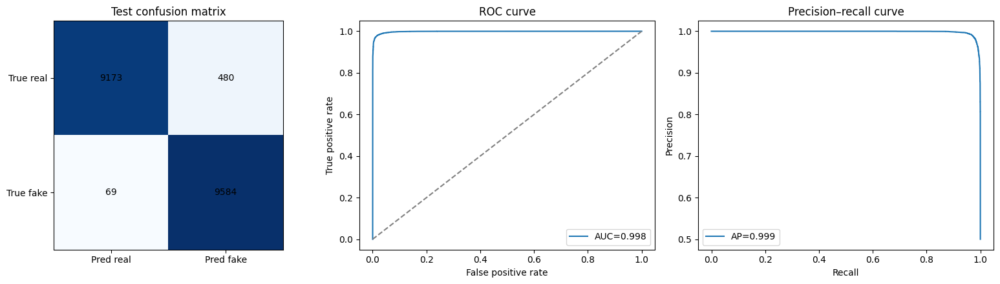

In [ ]:
# Confusion matrix, ROC curve, and precision-recall curve.
cm = confusion_matrix(y_test, pred_test, labels=[0, 1])
fpr, tpr, _ = roc_curve(y_test, prob_test)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, prob_test)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].imshow(cm, cmap="Blues")
for (i, j), value in np.ndenumerate(cm):
    axes[0].text(j, i, str(value), ha="center", va="center")
axes[0].set_xticks([0,1], ["Pred real", "Pred fake"])
axes[0].set_yticks([0,1], ["True real", "True fake"])
axes[0].set_title("Test confusion matrix")

axes[1].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, prob_test):.3f}")
axes[1].plot([0,1], [0,1], "--", color="gray")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve"); axes[1].legend()

axes[2].plot(recall_curve, precision_curve,
             label=f"AP={average_precision_score(y_test, prob_test):.3f}")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Precision–recall curve"); axes[2].legend()
plt.tight_layout(); plt.show()

### 7.2 Threshold selection on validation only

If the application values avoiding false negatives differently from avoiding false positives, a threshold other than 0.5 may be appropriate. This example selects the threshold maximizing validation F1. It then applies that fixed threshold to the test set once. Do not keep trying thresholds on the test set.

In [ ]:
thresholds = np.linspace(0.05, 0.95, 181)
val_f1 = [f1_score(y_val, prob_val >= t, zero_division=0) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(val_f1))])
print(f"Threshold selected on validation (max F1): {best_threshold:.3f}")
print(f"Validation F1 at 0.5: {f1_score(y_val, prob_val >= 0.5, zero_division=0):.4f}")
print(f"Validation F1 at selected threshold: {max(val_f1):.4f}")
_ = report_metrics(y_test, prob_test, best_threshold, "Test at validation-selected threshold")

Threshold selected on validation (max F1): 0.805
Validation F1 at 0.5: 0.9736
Validation F1 at selected threshold: 0.9822
--- Test at validation-selected threshold (n=19,306, threshold=0.805) ---
Accuracy:          0.9807
Precision (fake):  0.9781
Recall (fake):     0.9834
F1 (fake):         0.9807
ROC-AUC:           0.9985
Average Precision: 0.9985
TN=9,440 | FP=213 | FN=160 | TP=9,493
              precision    recall  f1-score   support

        real     0.9833    0.9779    0.9806      9653
        fake     0.9781    0.9834    0.9807      9653

    accuracy                         0.9807     19306
   macro avg     0.9807    0.9807    0.9807     19306
weighted avg     0.9807    0.9807    0.9807     19306



In [ ]:
# Bootstrap confidence interval for test accuracy.
# This describes sampling uncertainty under an IID test-sample assumption;
# it does not account for dataset/source bias or distribution shift.
N_BOOTSTRAP = 1000
correct = (pred_test == y_test).astype(np.float32)
boot_rng = np.random.default_rng(SEED)
boot_acc = np.empty(N_BOOTSTRAP)
for b in range(N_BOOTSTRAP):
    sample = boot_rng.integers(0, len(correct), size=len(correct))
    boot_acc[b] = correct[sample].mean()
lo, hi = np.percentile(boot_acc, [2.5, 97.5])
print(f"Test accuracy: {correct.mean():.4f}")
print(f"Percentile bootstrap 95% CI: [{lo:.4f}, {hi:.4f}]")

Test accuracy: 0.9716
Percentile bootstrap 95% CI: [0.9693, 0.9741]


### 7.3 Error analysis

False positives (real predicted fake): 480
False negatives (fake predicted real): 69


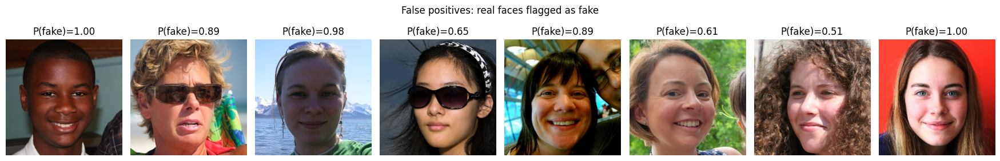

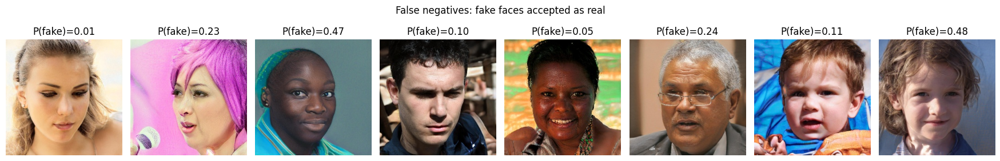

In [ ]:
fp_idx = np.where((y_test == 0) & (pred_test == 1))[0]
fn_idx = np.where((y_test == 1) & (pred_test == 0))[0]
print("False positives (real predicted fake):", len(fp_idx))
print("False negatives (fake predicted real):", len(fn_idx))

def display_errors(positions, title, max_images=8):
    if len(positions) == 0:
        print("No examples:", title)
        return
    local_rng = np.random.default_rng(SEED)
    chosen = local_rng.choice(positions, size=min(max_images, len(positions)), replace=False)
    fig, axes = plt.subplots(1, len(chosen), figsize=(2.2*len(chosen), 3))
    if len(chosen) == 1:
        axes = [axes]
    for ax, pos in zip(axes, chosen):
        row_idx = int(test_idx[pos])
        img = ds["test"][row_idx]["image"].convert("RGB")
        ax.imshow(img)
        ax.set_title(f"P(fake)={prob_test[pos]:.2f}")
        ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

display_errors(fp_idx, "False positives: real faces flagged as fake")
display_errors(fn_idx, "False negatives: fake faces accepted as real")

### 7.4 Calibration

A model is calibrated when, among predictions assigned probability around 0.8, roughly 80% are positive. High ROC-AUC does not guarantee good calibration. The reliability diagram below is descriptive; because it uses the test set, it must not be used to fit a calibration correction.

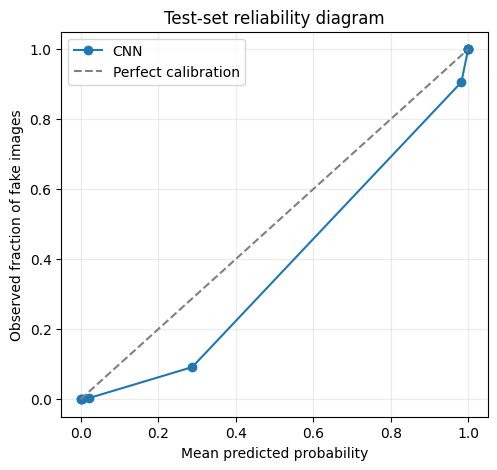

In [ ]:
from sklearn.calibration import calibration_curve
fraction_positive, mean_predicted = calibration_curve(y_test, prob_test, n_bins=10, strategy="quantile")
plt.figure(figsize=(5.5, 5))
plt.plot(mean_predicted, fraction_positive, marker="o", label="CNN")
plt.plot([0,1], [0,1], "--", color="gray", label="Perfect calibration")
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed fraction of fake images")
plt.title("Test-set reliability diagram"); plt.legend(); plt.grid(alpha=0.25)
plt.show()

### 7.5 Optional Grad-CAM explanation

Grad-CAM uses gradients flowing into a convolutional layer to highlight image regions associated with a model score. 

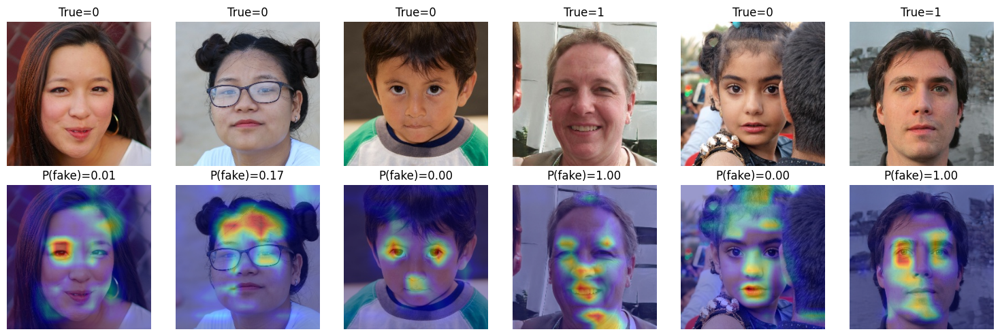

In [ ]:
RUN_GRADCAM = True
if RUN_GRADCAM:
    import torch.nn.functional as F
    for module in model.modules():
        if isinstance(module, nn.ReLU):
            module.inplace = False

    def gradcam_one(image_tensor, target_layer):
        cache = {}
        handle = target_layer.register_forward_hook(lambda module, inputs, output: cache.__setitem__("activation", output))
        logit = model(image_tensor)
        handle.remove()
        activation = cache["activation"]
        score = logit[0] if logit[0].item() >= 0 else -logit[0]
        gradients = torch.autograd.grad(score, activation)[0]
        weights = gradients.mean(dim=(2,3), keepdim=True)
        cam = F.relu((weights * activation).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=image_tensor.shape[-2:], mode="bilinear", align_corners=False)[0,0]
        cam = cam / (cam.max() + 1e-8)
        return cam.detach().cpu().numpy(), torch.sigmoid(logit[0]).item()

    target_layer = model.features[4][2]
    candidates = np.arange(len(test_idx))
    selected = np.random.default_rng(SEED).choice(candidates, size=min(6, len(candidates)), replace=False)
    fig, axes = plt.subplots(2, len(selected), figsize=(2.5*len(selected), 5))
    for col, pos in enumerate(selected):
        img = ds["test"][int(test_idx[pos])]["image"].convert("RGB")
        x = eval_tf(img).unsqueeze(0).to(device)
        cam, p_fake = gradcam_one(x, target_layer)
        axes[0, col].imshow(img); axes[0, col].set_title(f"True={y_test[pos]}")
        axes[1, col].imshow(img); axes[1, col].imshow(cam, cmap="jet", alpha=0.4)
        axes[1, col].set_title(f"P(fake)={p_fake:.2f}")
        axes[0, col].axis("off"); axes[1, col].axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Grad-CAM skipped. Set RUN_GRADCAM=True to run the optional visualization.")

## 8. Critical analysis

Interpret the metrics together rather than relying on accuracy alone:

- **Train–validation gap:** a much lower training loss than validation loss may indicate overfitting. Similar high losses can indicate underfitting or optimization problems.
- **False positives:** real faces incorrectly flagged as generated. These can reduce trust in a detector.
- **False negatives:** synthetic faces accepted as real. These may be especially concerning in screening applications.
- **ROC-AUC and Average Precision:** summarize ranking over thresholds, but do not select a deployment threshold by themselves.
- **Calibration:** probabilities may not correspond to true frequencies, especially after a change in image source or prevalence.
- **Data leakage:** duplicate or near-duplicate images crossing splits can inflate test performance. Hashes and index files should be audited, and approximate matches require manual/quantitative confirmation.
- **Source confounding:** if real images come from FFHQ and fake images from StyleGAN, the model may learn source-specific differences rather than universal synthetic-image cues.

The test score estimates performance on this dataset's held-out split only. Generalization to other generators, image resolutions, compression levels, or social-media images requires separate external testing.

## 9. Limitations and future work

### Limitations

1. The dataset contrasts a specific real-image source with a specific generator family, which can create source confounding.
2. Duplicate detection based on hashes is imperfect; perceptually similar images may not be duplicates, and different images may collide.
3. The CNN and training settings are relatively simple and may not represent the strongest current detection systems.
4. Results depend on hardware, runtime interruptions, image decoding, and the exact saved indices.
5. Grad-CAM provides coarse, model-dependent visual explanations and should not be interpreted as causal evidence.
6. An IID bootstrap confidence interval does not quantify uncertainty from distribution shift or dataset construction.

### Future work

- Test on independent datasets and images generated by different, newer model families.
- Evaluate robustness to JPEG compression, resizing, blur, and common social-media processing.
- Compare a CNN trained from scratch with transfer learning and frequency-aware methods.
- Assess calibration on a separate calibration set.
- Audit near-duplicate candidates and report exclusions transparently.
- Use broader external validation before considering practical deployment.

### external experiment: FaceForensics++

FaceForensics++ concerns manipulated video content and has a different source distribution from the face-image dataset used above.

## 10. References

1. Goodfellow, I. et al. (2014). *Generative Adversarial Nets*. Advances in Neural Information Processing Systems (NeurIPS). https://doi.org/10.48550/arXiv.1406.2661
2. Karras, T., Laine, S., & Aila, T. (2019). *A Style-Based Generator Architecture for Generative Adversarial Networks*. CVPR. https://doi.org/10.1109/CVPR.2019.00453
3. LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). *Gradient-Based Learning Applied to Document Recognition*. Proceedings of the IEEE, 86(11), 2278–2324. https://doi.org/10.1109/5.726791
4. Wang, S.-Y. et al. (2020). *CNN-Generated Images Are Surprisingly Easy to Spot... for Now*. CVPR. https://doi.org/10.1109/CVPR42600.2020.00821
5. Selvaraju, R. R. et al. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization*. ICCV. https://doi.org/10.1109/ICCV.2017.74
6. He, K. et al. (2016). *Deep Residual Learning for Image Recognition*. CVPR. https://doi.org/10.1109/CVPR.2016.90
7. Hugging Face. *Datasets documentation*. https://huggingface.co/docs/datasets
8. PyTorch. *PyTorch documentation*. https://pytorch.org/docs/stable/index.html
9. scikit-learn. *Metrics and scoring documentation*. https://scikit-learn.org/stable/modules/model_evaluation.html
10. TheKernel01. *140k Real and Fake Faces dataset*. https://huggingface.co/datasets/TheKernel01/140k-Real-and-Fake-Faces

The literature references above support the general methods discussed. Dataset-specific counts and all model performance metrics must be taken from the executed cells in this notebook.